# Üç Boyutlu Grafikler

Bu derste üçüncü boyuta çıkıyoruz: üç sayısal değişkeni tek grafikte birlikte göstereceğiz. matplotlib'in `mplot3d` aracıyla statik 3B dağılım ve yüzey grafikleri, plotly ile döndürülebilir etkileşimli 3B grafikler üreteceğiz. Ama bu dersin en önemli konusu araçlar değil: **3B'nin ne zaman doğru, ne zaman yanıltıcı olduğu.** 1. derste "yersiz üç boyut" hatasını görmüştük; bugün o konuya tam anlamıyla döneceğiz.

## 🎯 Bu Derste Ne Öğreneceğiz?

Bu dersin sonunda şunları yapabileceksin:

- `mplot3d` ile 3B dağılım ve yüzey grafikleri çizmek
- `meshgrid` ile iki değişkenli bir fonksiyonun yüzeyini üretmek
- plotly ile döndürülebilir 3B dağılım ve yüzey grafikleri üretmek
- Görünüm açısını (`view_init`, `camera`) bilinçli seçmek
- 3B grafiklerin yanıltıcı kullanım örneklerini teşhis etmek

Bu ders, kursun 8. öğrenme çıktısını tamamlıyor ve 10. çıktısına (grafik eleştirisi) hizmet ediyor.

## 💡 Neden Bu Konuyu Öğreniyoruz?

10. dersteki öğrenci verisinde üç sayısal değişken bir arada işliyordu: çalışma saati, sosyal medya ve not. Pairplot bunu ikili kombinasyonlarla gösterdi; korelasyon haritası sayılarla özetledi. Peki üç değişkenin **aynı anda** örüntüsünü tek bir bakışta görmek istersek? İşte 3B dağılım grafiğinin asıl işi budur.

Yüzey grafikleri ise farklı bir ihtiyaçtır: iki bağımsız değişkenin bir sonucu nasıl etkilediğini (bir matematiksel modeli ya da simülasyonu) sürekli bir tepede göstermek. 3B aynı zamanda görselleştirmenin en çok suistimal edilen alanıdır: pasta grafiğe derinlik efekti katmak, çubuklara perspektif vermek... 1. derste öğrendiğimiz "oranı bozan efektler" 3B'de katlanarak büyür. Bu ders hem aracı hem de şeytanı tanıtır.

## 🔗 Ön Bilgi

- [Matplotlib Temelleri](07-Matplotlib-Basics.ipynb) ve [İleri Düzey](08-Matplotlib-Advanced.ipynb): figure-axes yapısı (`fig, ax`), etiketler, renk haritaları.
- [Seaborn İleri Düzey](10-Seaborn-Advanced.ipynb): öğrenci verisi ve değişken ilişkileri (bu dersin verisi).
- [Etkileşimli Grafikler: plotly](12-Interactive-Plots.ipynb): renderer deseni (etkileşimli hücre + PNG kopyası).

## 🔍 Birlikte Keşfedelim

Öğrenci verisini yükleyip bildiğimiz 2B dağılım grafiğini çizelim: çalışma saati ve vize notu. **Tahminin:** Bu grafiğe sosyal medya kullanımını üçüncü değişken olarak eklersek örüntü netleşir mi, karmaşıklaşır mı? Tahminini yaz, sonra 3B sürümü karşılaştır:

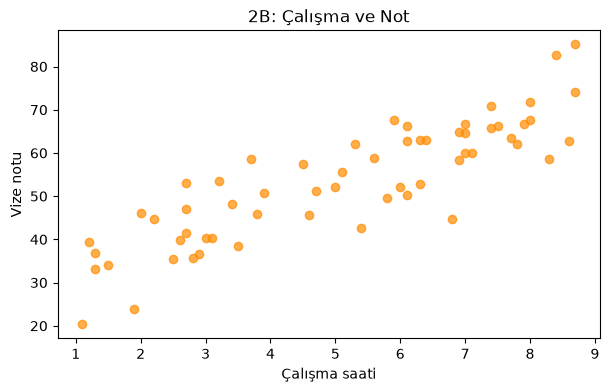

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ogrenci = pd.read_csv("../Data/10-student-habits.csv")

plt.figure(figsize=(7, 4))
plt.scatter(ogrenci["calisma_saati"], ogrenci["vize_notu"],
            alpha=0.7, color="darkorange")
plt.title("2B: Çalışma ve Not")
plt.xlabel("Çalışma saati")
plt.ylabel("Vize notu")
plt.show()

Şimdi aynı veriyi üç eksene taşıyalım. `fig.add_subplot(..., projection="3d")` bir axes'i 3B moda sokar; `ax.scatter` artık üç koordinat alır:

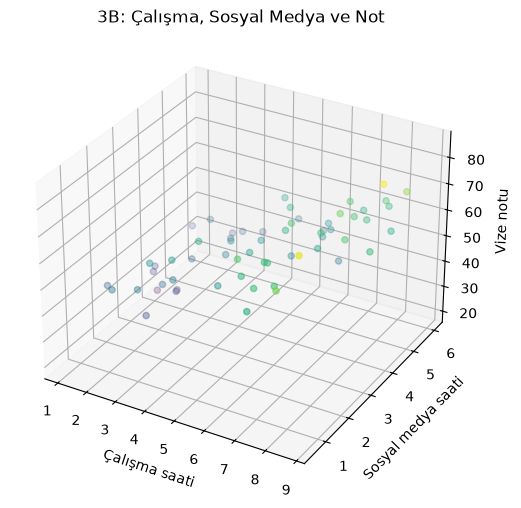

In [2]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(ogrenci["calisma_saati"], ogrenci["sosyal_medya_saati"],
           ogrenci["vize_notu"], c=ogrenci["vize_notu"], cmap="viridis",
           alpha=0.8)

ax.set_xlabel("Çalışma saati")
ax.set_ylabel("Sosyal medya saati")
ax.set_zlabel("Vize notu")
ax.set_title("3B: Çalışma, Sosyal Medya ve Not")
plt.show()

**Gözlem:** Statik 3B grafikte noktalar bir "eğimli bulut" oluşturuyor: çalışma arttıkça ve sosyal medya azaldıkça not yükseliyor. Ama dürüst olalım — statik 3B grafikte derinliği okumak zor: hangi nokta önde, hangi arkada? Renk eşlemesi (`c=not`) bu belirsizliği biraz azaltıyor. Tam da bu yüzden 3B grafikler genelde **etkileşimli** ister; aşağıda plotly ile döndürülebilir versiyonu yapacağız.

## 📖 Kavramlar

**3B dağılım grafiği (scatter_3d):** Her nokta üç sayısal değişkenin kesişimidir. Dördüncü bilgi renkle taşınabilir. Doğru kullanım: üç sayısal değişkenin **ortak örüntüsü** merak edildiğinde.

**Yüzey grafiği (surface plot):** İki bağımsız değişken (x, y) düzleminde her nokta için hesaplanan z değerinin oluşturduğu sürekli tepe. Matematiksel modeller, simülasyonlar ve "iki girdi bir çıktı" ilişkileri için kullanılır.

**`meshgrid`:** x ve y eksen değerlerini iki boyutlu ızgaraya genişletir; her (x, y) kesişimi için z hesaplanır. Yüzey grafiklerinin veri hazırlık adımıdır.

**Görünüm açısı:** Statik 3B grafiklerde `ax.view_init(elev, azim)` (yükselme ve azimut) bakış açısını belirler. Açı değişince aynı veri bambaşka görünebilir — 3B'nin gücü ve tehlikesi budur.

**Algısal tehlikeler:** Perspektif, uzaklık oranları bozar (öndeki büyük görünür); örtüşme (occlusion) arkadaki veriyi saklar; sabit olmayan bakış açısı okuyucuları farklı sonuçlara götürür. Kategorik veri için 3B çubuk/pasta grafikleri bu yüzden neredeyse her zaman hatalı seçimdir.

## 🛠️ Uygulama

### 1) Yüzey grafiği: iki değişkenli bir fonksiyon

Klasik bir örnek: z = sin(√(x² + y²)). `meshgrid` ile ızgarayı kurup her noktanın z'sini hesaplıyoruz:

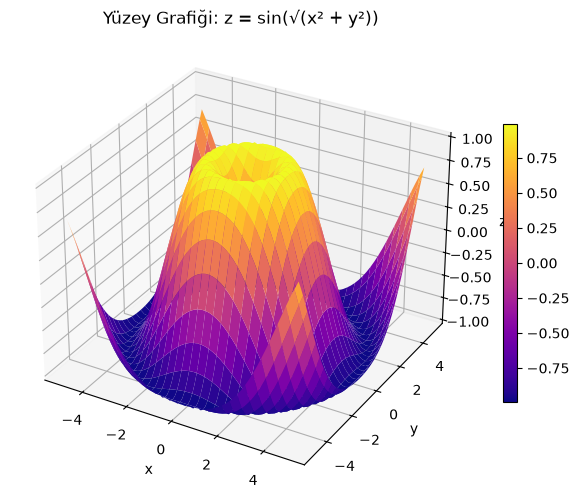

In [3]:
x = np.linspace(-5, 5, 60)
y = np.linspace(-5, 5, 60)
X, Y = np.meshgrid(x, y)
Z = np.sin(np.sqrt(X**2 + Y**2))

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")

yuzey = ax.plot_surface(X, Y, Z, cmap="plasma")
fig.colorbar(yuzey, shrink=0.6)

ax.set_title("Yüzey Grafiği: z = sin(√(x² + y²))")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
plt.show()

**Gözlem:** Merkezde bir tepe, etrafında halkalar — dalga yayılımına benzeyen bu şekil, fonksiyonun "coğrafyası"dır. `colorbar` z değerlerini renklere bağlar (2. dersin sıralı paleti: sayısal büyüklük). Böyle bir grafik, "bu fonksiyon nerede yükselir?" sorusuna sözlü yanıttan çok daha hızlı cevap verir.

### 2) Etkileşimli 3B dağılım: plotly

Statik 3B'nin derinlik okuma sorununu çözmek için grafiği döndürülebilir yapalım (12. dersteki renderer desenini koruyarak):

In [4]:
import plotly.express as px
import plotly.io as pio

pio.renderers.default = "notebook_connected"

fig = px.scatter_3d(ogrenci, x="calisma_saati", y="sosyal_medya_saati",
                    z="vize_notu", color="bolum",
                    title="Öğrenci Alışkanlıkları: 3B Keşif")
fig.update_layout(scene=dict(
    xaxis_title="Çalışma saati",
    yaxis_title="Sosyal medya saati",
    zaxis_title="Vize notu"))
fig.show()

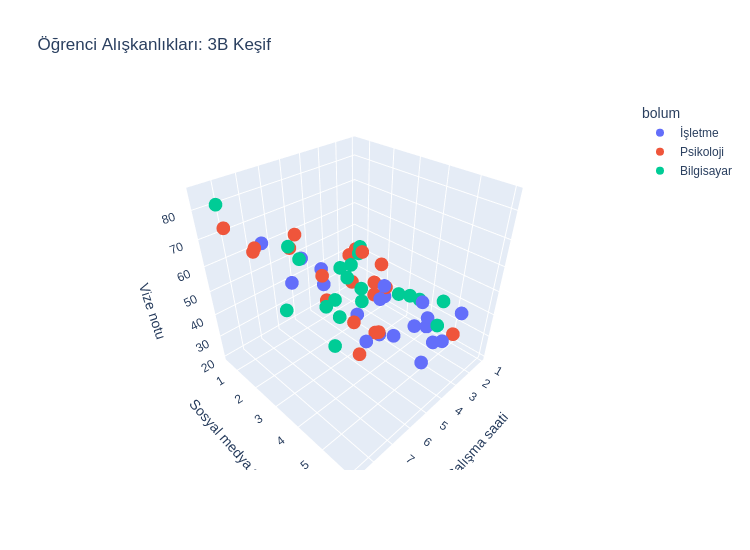

In [5]:
fig.show(renderer="png", width=750, height=550)

Kendi ortamında grafiği **döndür**: sürükleyerek farklı açılardan bak. Aynı veri, her açıda başka bir hikâye anlatır gibi görünür — ama örüntü (yüksek not = çok çalışma + az sosyal medya) her açıda korunur; işte 3B'nin işe yaradığı durum budur. Bölümler renklerle ayrılmış; legend'dan açıp kapatabilirsin.

### 3) Etkileşimli yüzey: plotly

In [6]:
import plotly.graph_objects as go

Z2 = np.cos(X) * np.sin(Y)

fig = go.Figure(data=[go.Surface(z=Z2, x=X, y=Y,
                                 colorscale="Viridis")])
fig.update_layout(title="Etkileşimli Yüzey: z = cos(x)·sin(y)",
                  scene=dict(xaxis_title="x", yaxis_title="y", zaxis_title="z"))
fig.show()

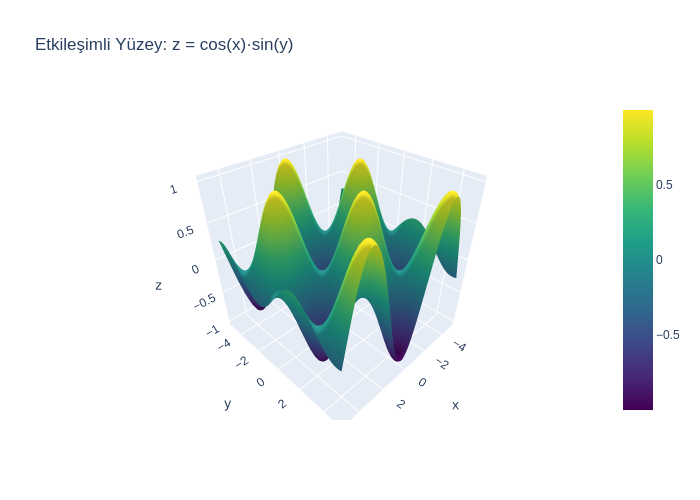

In [7]:
fig.show(renderer="png", width=700, height=500)

### 4) Yanıltıcı 3B üretmek (ve teşhis etmek)

1. dersin "yersiz üç boyut" hatasını kendimiz üretelim: **kategorik** veriyi 3B çubuklara dökmek. Aşağıdaki grafik şehir-ürün satışlarını üç boyutta gösteriyor:

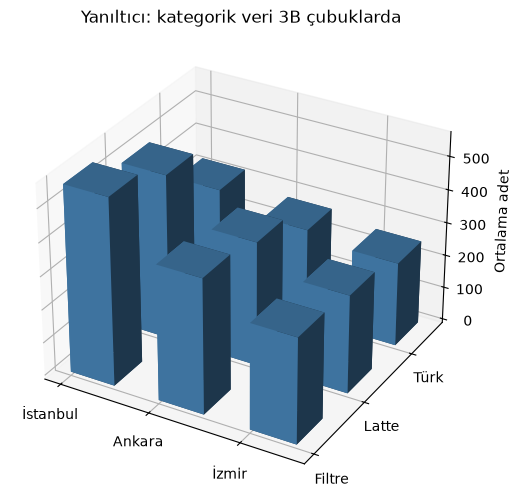

In [8]:
satis = pd.read_csv("../Data/05-coffee-sales.csv")
kirilim = satis.groupby(["sehir", "urun"])["adet"].mean().reset_index()

x_pos = kirilim["sehir"].map({"İstanbul": 0, "Ankara": 1, "İzmir": 2})
y_pos = kirilim["urun"].map({"Filtre Kahve": 0, "Latte": 1, "Türk Kahvesi": 2})

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
ax.bar3d(x_pos, y_pos, 0, 0.5, 0.5, kirilim["adet"], shade=True, color="steelblue")

ax.set_xticks([0, 1, 2], ["İstanbul", "Ankara", "İzmir"])
ax.set_yticks([0, 1, 2], ["Filtre", "Latte", "Türk"])
ax.set_zlabel("Ortalama adet")
ax.set_title("Yanıltıcı: kategorik veri 3B çubuklarda")
plt.show()

**Gözlem:** Bu grafiği okumaya çalış: Ankara'nın Latte'si mi büyük, İstanbul'un Türk kahvesi mi? Perspektif yüzünden öndeki çubuklar büyük, arka plan küçük görünüyor; birbirini örten çubuklar karşılaştırmayı bozuyor. Aynı verinin doğru sunumu 10. dersten tanıdığın çözüm: gruplu 2B çubuklar ya da ısı haritası. 3B çubuk, üçüncü boyutun **bilgi değil perspektif** taşıdığı durumlardır — kuralımız şu: üçüncü eksen gerçek bir sayısal değişken değilse, 3B kullanma.

### 5) Kodu tamamla (TODO)

In [9]:
# TODO: Öğrenci verisiyle başka bir 3B dağılım üret:
# x = uyku_saati, y = kahve_fincan, z = vize_notu (renk: bolum).
# Önce tahmin et: bu üçlüde hangi örüntü görünür? Sonra çiz ve karşılaştır.

# fig = px.scatter_3d(...)
# fig.show()
# fig.show(renderer="png", width=750, height=550)

print("Kontrol: uyku-not korelasyonu:",
      round(ogrenci['uyku_saati'].corr(ogrenci['vize_notu']), 2))

Kontrol: uyku-not korelasyonu: 0.02


Çözüm "Cevaplar" bölümünde.

## 🧪 Deneyelim ve Gözlemleyelim

**Deney 1:** Statik 3B dağılım grafiğinin bakış açısını değiştir: `ax.view_init(elev=10, azim=0)`, `ax.view_init(elev=45, azim=45)` ve `ax.view_init(elev=80, azim=90)` ile yeniden çiz. Üç görüntüde örüntü aynı mı algılanıyor? Hangisi en dürüst?

**Deney 2:** Yüzey grafiğinin çözünürlüğünü değiştir: `np.linspace(-5, 5, 60)` yerine `10` ve `200` dene. Izgara seyrekleşince ve yoğunlaşınca ne oluyor?

**Deney 3:** plotly 3B dağılımda noktaların saydamlığını değiştir: `fig.update_traces(opacity=0.4)`. Örtüşme sorunu azalıyor mu?

## 🧯 Bir Şeyler Ters Giderse

| Belirti | Olası neden | Çözüm |
|---|---|---|
| `AttributeError: 'AxesSubplot' object has no attribute 'set_zlabel'` | `projection="3d"` unutuldu | Axes'i `fig.add_subplot(111, projection="3d")` ile kur |
| `ValueError: z array... shape mismatch` (yüzey) | `meshgrid` atlandı ya da boyutlar uyuşmadı | X, Y, Z aynı ızgara boyutunda olmalı; `Z.shape` ile kontrol et |
| Statik 3B grafik "düz" görünüyor | Varsayılan görünüm açısı veriye uymuyor | `ax.view_init(elev=..., azim=...)` ile açıyı seç |
| plotly 3B boş görünüyor | Renderer/internet (12. ders) | `fig.show()`'u yeniden çalıştır; statik PNG kopyasına bak |
| Renk ekseni anlamsız | `c` parametresi yanlış sütuna bağlandı | Renk, taşımak istediğin değişkene bağlanmalı (ör. not) |
| 3B grafik "havalı" ama okunamıyor | Belki de 3B gerekmiyordur | 2B alternatifini çiz (facet, renk, ısı haritası); hâlâ daha iyiyse 3B kalsın |

> **İpucu:** 3B grafik çizmeden önce kendine sor: üçüncü boyut gerçek bir sayısal değişken mi? Etkileşim (döndürme) var mı? İki sorudan birine "hayır" cevabı çoğu zaman 2B çözümün daha iyi olduğunu söyler.

## 🏋️ Kendin Dene

1. **Açı turu:** Etkileşimli 3B dağılım grafiğini beş farklı açıdan incele; her açıda gördüğün örüntüyü tek cümleyle not et. Hangi açılar yanıltıcı, hangisi açıklayıcı?
2. **Yüzey değişimi:** `Z = X * np.exp(-X**2 - Y**2)` fonksiyonunun yüzeyini çiz (hem matplotlib hem plotly). Bu yüzey ne anlatıyor? Zirve nerede?
3. **Savunma:** Yanıltıcı 3B çubuk grafiğini bir arkadaşına göster ve "bu grafikte üç sorun var, bul" de. Cevap anahtarını kendin hazırla (perspektif, örtüşme, gereksiz boyut).

<details>
<summary>İpucu</summary>

2. görevdeki fonksiyon, iki boyutlu bir Gauss tepeciğidir: zirve (0, 0) noktasındadır ve uzaklaştıkça sıfıra iner. 3. görev için 1. dersin yanıltıcı grafik listesi ve bu dersin "algısal tehlikeler" paragrafını kullan.

</details>

## 🧠 Öğrendiklerini Kontrol Et

Cevaplar defterin sonundaki "Cevaplar" bölümünde. Önce kendin dene.

1. 3B dağılım grafiği hangi durumlarda 2B dağılım grafiğine tercih edilir? Bir örnek ver.
2. `meshgrid` ne yapar; yüzey grafiği hangi tür ilişkiyi gösterir?
3. Statik 3B grafiklerin derinlik okuma sorunlarını iki kelimeyle adlandır ve açıkla (perspektif ve ...?).
4. Şehir-ürün satışlarını 3B çubukla göstermek neden hatalı? Doğru alternatifler neler?
5. `view_init(elev, azim)` neyi kontrol eder ve bu kontrol neden sorumluluk ister?
6. Bu dersteki plotly 3B grafikleri "etkileşimli hücre + PNG kopyası" deseniyle üretildi. Deseni 12. dersten hatırla: PNG kopyası kimin için var?

## 🚀 Bağımsız Çalışma

- **Klasik veri seti:** plotly'nin iris veri seti (`px.data.iris()` — internet indirir) üç çiçek türünün ölçümlerini taşır. 3B dağılım grafiğini tür renkleriyle üret; türler 3B'de ayrışıyor mu? Ayrışma 2B scatter'lardan daha net mi?
- **Araştırma:** "3D pie chart neden kötü bir fikir?" sorusunu araştır ve 1. dersteki hata listesiyle birleştirip üç maddelik bir uyarı listesi yaz.

## 📚 Daha Fazlasını Öğrenmek

- matplotlib 3B araç seti eğitimi: https://matplotlib.org/stable/tutorials/toolkits/mplot3d.html
- plotly 3B grafikler: https://plotly.com/python/3d-charts/

İngilizcedir; kodlar doğrudan çalıştırılabilir.

## ✅ Kısa Özet

- 3B dağılım grafiği üç sayısal değişkenin ortak örüntüsünü taşır; dördüncü bilgi renkle eklenebilir.
- Yüzey grafikleri `meshgrid` ile hazırlanan iki bağımsız değişkenli fonksiyonların "coğrafyasını" gösterir.
- Statik 3B'de perspektif ve örtüşme okumayı zorlaştırır; etkileşimli 3B (plotly) döndürme ile bunu çözer.
- Kategorik veri için 3B çubuk/pasta neredeyse her zaman yanıltıcıdır: üçüncü boyut bilgi değil perspektif taşır.
- Bakış açısı (`view_init`, kamera) bir tasarım kararıdır; aynı veri farklı açılardan farklı algılanır.
- 3B'ye geçmeden önce daima 2B alternatif (renk, facet, ısı haritası) düşün.

Sıradaki derste ürettiğimiz her şeyi iletişim aracına çeviriyoruz: veriyle hikâye anlatımı.

---

[← Önceki ders: Coğrafi Görselleştirme: folium](13-Geographical-Maps.ipynb) · [Sıradaki ders: Veriyle Hikâye Anlatımı →](15-Data-Storytelling.ipynb)

## Cevaplar

<details>
<summary>Uygulama 5: uyku-kahve-not 3B'si (TODO çözümü)</summary>

```python
fig = px.scatter_3d(ogrenci, x="uyku_saati", y="kahve_fincan",
                    z="vize_notu", color="bolum",
                    title="Uyku, Kahve ve Not")
fig.update_layout(scene=dict(
    xaxis_title="Uyku saati",
    yaxis_title="Kahve (fincan)",
    zaxis_title="Vize notu"))
fig.show()
fig.show(renderer="png", width=750, height=550)
```

Beklenen gözlem: uyku-not korelasyonu zayıftı (kontrol hücresinde yaklaşık 0.0 civarı), kahve-not güçlüydü. 3B'de noktalar not ekseninde kahve artışına paralel yükselir; uyku ekseninde belirgin bir örüntü yoktur — verinin dürüst sunduğu budur.

</details>

<details>
<summary>Kontrol Et 1</summary>

Üç sayısal değişkenin ortak örüntüsü merak edildiğinde ve 2B çiftler (pairplot) yetersiz kaldığında. Örnek: çalışma ve sosyal medyanın notu **birlikte** nasıl etkilediği; kümelerin 3B'de ayrışması.

</details>

<details>
<summary>Kontrol Et 2</summary>

`meshgrid`, x ve y eksen değerlerini tüm kesişimleri içeren iki boyutlu ızgaraya genişletir; her (x, y) noktası için z hesaplanır. Yüzey grafiği, iki bağımsız değişkenin belirlediği bir sonucun (bağımlı değişkenin) sürekli değişimini gösterir.

</details>

<details>
<summary>Kontrol Et 3</summary>

Perspektif ve örtüşme (occlusion). Perspektif uzaklık oranlarını bozar (öndeki büyük görünür); örtüşme öndeki noktaların arkadakileri saklamasına yol açar.

</details>

<details>
<summary>Kontrol Et 4</summary>

Çünkü üçüncü boyut gerçek bir sayısal değişken değil, yalnızca perspektif efekti taşıyor; oran karşılaştırmasını bozuyor. Doğru alternatifler: gruplu 2B çubuk grafiği, ısı haritası (şehir×ürün pivot'u) ya da facet paneller.

</details>

<details>
<summary>Kontrol Et 5</summary>

Bakış açısını: yükselme (elev) ve azimut (azim). Sorumluluk ister çünkü aynı veri farklı açılardan farklı algılanır; açı, mesajı desteklemeli, çarpıtmamalıdır.

</details>

<details>
<summary>Kontrol Et 6</summary>

GitHub'da okuyan için. Etkileşimli çıktı JavaScript'tir ve GitHub önizlemesinde görünmez; PNG kopyası her ortamda görünen statik görüntüdür.

</details>